# Experimental: cross-section with orography from surface pressure

**This is an experimental example.** It extends the first cross-section notebook, [cross_section.ipynb](cross_section.ipynb), with the orography. It shows the same temperature cross-section along a line and adds surface pressure (`sp`), regridded onto the same line. The surface pressure is drawn as a filled black polygon, which marks the ground. It is similar to the Metview gallery example [Cross Section with Orography and Boundary Layer Height](https://metview.readthedocs.io/en/latest/gen_files/gallery/cross_section_orog_and_blh.html), but it uses only the surface pressure and no boundary layer height. It also uses the new `earthkit.geo.polyline` module, whose interface may still change.

The notebook reads a GRIB file.

To make this notebook work [earthkit-data](https://earthkit-data.readthedocs.io), [earthkit-plots](https://earthkit-plots.readthedocs.io) and xarray have to be installed.

## Imports

In [1]:
from datetime import datetime, timedelta

import earthkit.data as ekd
import earthkit.geo as ekg
import earthkit.plots as ekp
import numpy as np
import xarray as xr
from earthkit.geo.distance import haversine_distance
from earthkit.geo.polyline import sample_polyline

## Load the data

The file contains surface pressure (`sp`) and temperature, wind components and vertical velocity (`t`, `u`, `v`, `w`) on the pressure levels 1000, 850, 700, 500, 400 and 300 hPa, for the forecast steps 12, 18 and 24 h from the base date 2011-12-15 12 UTC (75 fields). All fields are on the same regional regular latitude-longitude grid with a 1° resolution, covering 40°N–56°N and 10°W–10°E. Here is a short listing of the first fields.

In [2]:
ds = ekd.from_source("sample", "xs_pl_input.grib1").to_fieldlist()
print(len(ds), "fields")
ds[:6].ls()

xs_pl_input.grib1:   0%|          | 0.00/61.5k [00:00<?, ?B/s]

75 fields


,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,u,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,1000,pressure,0,regular_ll
1,v,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,1000,pressure,0,regular_ll
2,w,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,1000,pressure,0,regular_ll
3,t,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,1000,pressure,0,regular_ll
4,u,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,850,pressure,0,regular_ll
5,v,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,850,pressure,0,regular_ll


## Select the temperature and the surface pressure

We select the fields for the base date 2011-12-15 12 UTC and the forecast step of 12 h. Temperature gives one field for each of the 6 pressure levels. Surface pressure gives a single field in pascal.

In [3]:
base_date = datetime(2011, 12, 15, 12)
step = timedelta(hours=12)

t = ds.sel({
    "parameter.variable": "t",
    "time.base_datetime": base_date,
    "time.step": step,
})
sp = ds.sel({
    "parameter.variable": "sp",
    "time.base_datetime": base_date,
    "time.step": step,
})
levels = [f.get("vertical.level") for f in t]
print(len(t), "t fields, levels (hPa):", levels)
print(len(sp), "sp field")

6 t fields, levels (hPa): [1000, 850, 700, 500, 400, 300]
1 sp field


## Define the line

[sample_polyline()](https://earthkit-geo.readthedocs.io) returns the latitudes and longitudes of 200 points along the great circle between (40°N, 10°W) and (56°N, 10°E). The points are evenly spaced along the line and include both end points.

In [4]:
lats, lons = sample_polyline([40, 56], [-10, 10], n=200)
print(lats.shape, (lats[0], lons[0]), (lats[-1], lons[-1]))

(200,) (np.float64(40.0), np.float64(-10.0)) (np.float64(56.0), np.float64(10.0))


## Regrid onto the line

Temperature and surface pressure are regridded onto the same 200 points, which are given as an unstructured target grid. The default linear interpolation is used. The result is a fieldlist with one field of 200 values for each pressure level for temperature, and a single field for surface pressure. The C library may print some `ECCODES WARNING` lines during this step (the input is GRIB edition 1, so the unstructured output grid is written in a higher edition), they do not stop the regridding.

In [5]:
out_grid = {"latitudes": lats.tolist(), "longitudes": lons.tolist()}

t_line = ekg.regrid(t, out_grid=out_grid)
sp_line = ekg.regrid(sp, out_grid=out_grid)
print(len(t_line), "t fields, shape of the values:", t_line[0].values.shape)
print(len(sp_line), "sp field, shape of the values:", sp_line[0].values.shape)

6 t fields, shape of the values: (200,)
1 sp field, shape of the values: (200,)


ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!


## Build an Xarray Dataset

We build a Dataset with the temperature `t` on the dimensions `level` (hPa) and `distance` (km), and the surface pressure `sp` on `distance` only. The surface pressure is converted from pascal to hPa, so it is in the same unit as the vertical axis. The distance is measured along the line from its first point, using the haversine distance (in metres, so we divide by 1000). This is valid because the line is one single great circle segment. The latitudes and longitudes of the points are stored as auxiliary coordinates of `distance`. The levels are sorted in ascending order.

In [6]:
distance = haversine_distance((lats[0], lons[0]), (lats, lons)) / 1000

xs = xr.Dataset(
    {
        "t": (
            ("level", "distance"),
            np.stack([f.values for f in t_line]),
            {"units": "K", "long_name": "Temperature"},
        ),
        "sp": (
            ("distance",),
            sp_line[0].values / 100,
            {"units": "hPa", "long_name": "Surface pressure"},
        ),
    },
    coords={
        "level": ("level", levels, {"units": "hPa"}),
        "distance": ("distance", distance, {"units": "km"}),
        "latitude": ("distance", lats, {"units": "degrees_north"}),
        "longitude": ("distance", lons, {"units": "degrees_east"}),
    },
).sortby("level")
xs

<xarray.Dataset> Size: 16kB
Dimensions:    (level: 6, distance: 200)
Coordinates:
  * level      (level) int64 48B 300 400 500 700 850 1000
  * distance   (distance) float64 2kB 0.0 11.57 23.14 ... 2.291e+03 2.302e+03
    latitude   (distance) float64 2kB 40.0 40.09 40.17 ... 55.86 55.93 56.0
    longitude  (distance) float64 2kB -10.0 -9.926 -9.853 ... 9.725 9.862 10.0
Data variables:
    t          (level, distance) float64 10kB 234.2 234.2 234.1 ... 276.4 276.3
    sp         (distance) float64 2kB 1.028e+03 1.028e+03 ... 987.1 986.8

## Plot the cross-section with the orography

We plot the filled contours of temperature with a non-map earthkit-plots `Subplot`. The colour bar is added with the `legend()` method of the figure. The orography is added afterwards with `fill_between()`, so it is drawn on top of the temperature: it fills the area in black from the surface pressure down to 1000 hPa. Black marks the ground, i.e. everything below the surface pressure. The vertical axis limits are set explicitly with 1000 hPa at the bottom and 300 hPa at the top. The horizontal axis has 7 evenly spaced ticks, each labelled with the latitude and longitude of the nearest sampled point, rounded to whole degrees.

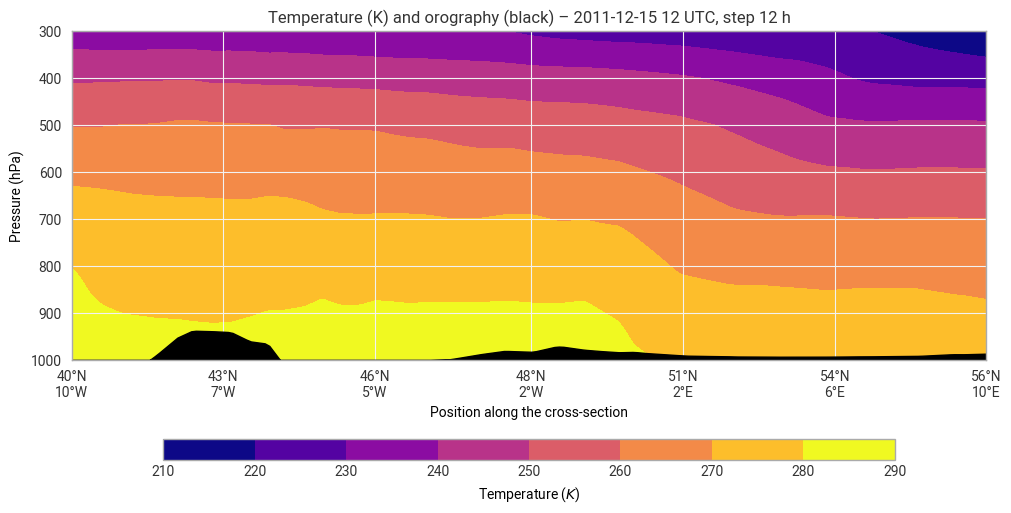

In [7]:
def fmt_lat(lat):
    lat = int(round(lat))
    return f"{abs(lat)}°N" if lat > 0 else f"{abs(lat)}°S" if lat < 0 else "0°"


def fmt_lon(lon):
    lon = int(round(lon))
    return f"{abs(lon)}°E" if lon > 0 else f"{abs(lon)}°W" if lon < 0 else "0°"


# 7 evenly spaced points along the line
idx = np.linspace(0, len(lats) - 1, 7).round().astype(int)
tick_labels = [f"{fmt_lat(lats[i])}\n{fmt_lon(lons[i])}" for i in idx]

chart = ekp.Subplot(figsize=(10, 5))
chart.contourf(xs["t"], x="distance", y="level")
chart.figure.legend()
# orography: black polygon from the surface pressure down to 1000 hPa, drawn on top
chart.fill_between(xs["sp"], 1000, x=xs["distance"], color="black", alpha=1)

ax = chart.ax
ax.set_ylim(1000, 300)  # 1000 hPa at the bottom, 300 hPa at the top
ax.set_xticks(distance[idx])
ax.set_xticklabels(tick_labels)
ax.set_xlabel("Position along the cross-section")
ax.set_ylabel("Pressure (hPa)")
ax.set_title(
    f"Temperature (K) and orography (black) – {base_date:%Y-%m-%d %H} UTC, step {step.total_seconds() / 3600:g} h"
)

chart.show()